# Fast Fashion Network: market model and hub removal (Model 2)

Student Name : Radiah, Flora

Five producer countries (X–W) sell clothing to two markets (A, B). Producer sizes come from the real top 5 exporters, the market sets one world price, and we test what happens when the biggest producer (the hub) loses factories.

## Setup

In [1]:
import os, zipfile
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.optimize import brentq      # finds the price where supply = demand

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

# Colours: one per producer (biggest first) and one for the markets
PROD_COLORS = ["#264653", "#2a9d8f", "#d9a62e", "#f4a261", "#e76f51"]
MARKET_COLOR = "#6d597a"
ATTACK_COLOR, RANDOM_COLOR = "#e76f51", "#2a9d8f"

# Find the dataset: local folder -> zip -> clone the repo (Colab)
DATA = "fast_fashion_dataset"
if not os.path.isdir(DATA):
    if os.path.isfile(DATA + ".zip"):
        zipfile.ZipFile(DATA + ".zip").extractall(".")
    else:
        if not os.path.isdir("repo"):
            os.system("git clone -q https://github.com/radiah23/Modeling-Fast-Fashion-Supply-Chain.git repo")
        DATA = "repo/fast_fashion_dataset"

---
# 1. The world

The real top 5 clothing exporters (China, Bangladesh, Vietnam, Turkey, India) have very unequal sizes. Sorted by size, their shares follow a power law in rank, $s_r \propto r^{-\alpha}$. We fit $\alpha$ once and use it to build **generic producers X, Y, Z, V, W** whose shares add up to 1. All producers get the same wage, so size is the only difference between them. Markets A and B take 70% and 30% of demand, like the EU and the USA.

In [2]:
prod = pd.read_csv(f"{DATA}/producers.csv").nlargest(5, "exports_2024_usd_bn")
cons = pd.read_csv(f"{DATA}/consumers.csv").set_index("iso3").loc[["EU", "USA"]]

# Hub strength alpha: slope of log(share) vs log(rank)
real_share = prod.exports_2024_usd_bn.values / prod.exports_2024_usd_bn.sum()
rank = np.arange(1, 6)
ALPHA = -np.polyfit(np.log(rank), np.log(real_share), 1)[0]

PRODUCERS, MARKETS = ["X", "Y", "Z", "V", "W"], ["A", "B"]
P0 = rank ** -ALPHA; P0 = P0 / P0.sum()                                   # producer shares, add up to 1
C0 = (cons.imports_2023_usd_bn / cons.imports_2023_usd_bn.sum()).values  # market shares (EU, USA)
COLORS = dict(zip(PRODUCERS, PROD_COLORS))

print(f"alpha = {ALPHA:.2f}")
display(pd.DataFrame({"real country": prod.country.values, "real share": real_share.round(3),
                      "generic": PRODUCERS, "model share": P0.round(3)}))

alpha = 1.42


,real country,real share,generic,model share
0,China,0.608,X,0.549
1,Bangladesh,0.142,Y,0.205
2,Vietnam,0.125,Z,0.115
3,Turkey,0.066,V,0.076
4,India,0.060,W,0.056


---
# 2. The network

Edges go from producers to markets. We only know the totals, so we use **proportional allocation**, $w_{ij} = P_i \cdot C_j / Q$: each producer splits its output in the same proportions as the markets' demand. This is the standard (maximum-entropy) assumption and the same idea as the null model $k_i k_j / 2m$ in modularity (Week 5).

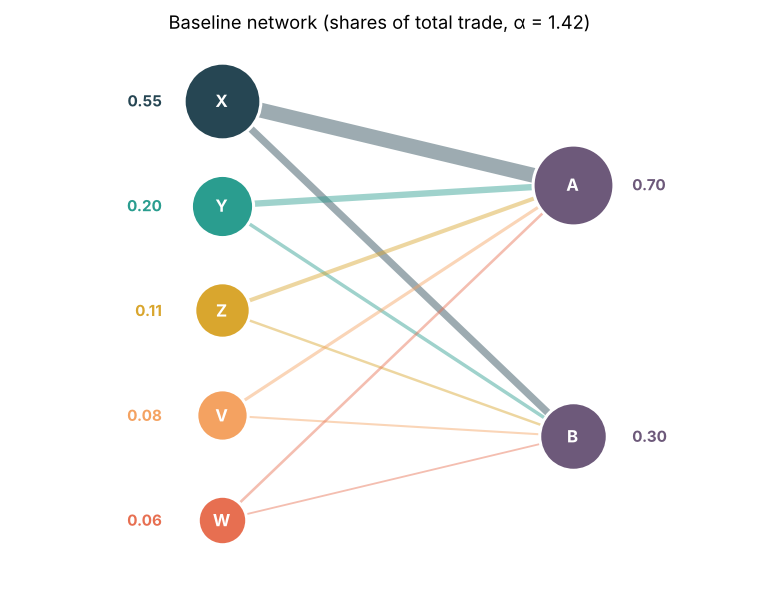

In [3]:
def build_network(P, C):
    """Bipartite producer -> market network with proportional allocation."""
    G = nx.DiGraph()
    for i, p in zip(PRODUCERS, P): G.add_node(i, size=p, kind="producer")
    for j, c in zip(MARKETS, C):   G.add_node(j, size=c, kind="market")
    for i, p in zip(PRODUCERS, P):
        for j, c in zip(MARKETS, C):
            G.add_edge(i, j, weight=p * c / C.sum())
    return G

def draw_network(G, ax, title, before=None):
    """Producers left, markets right. Node area ~ size, edge width ~ flow.
    before = network before a shock: producers that lost output get a dashed ring."""
    pos = {n: (0, -k) for k, n in enumerate(PRODUCERS)}
    pos.update({"A": (1, -0.8), "B": (1, -3.2)})
    ref = before if before is not None else G             # same edge scale before and after a shock
    wmax = max(d["weight"] for *_, d in ref.edges(data=True))
    for u, v, d in G.edges(data=True):
        ax.plot(*zip(pos[u], pos[v]), color=COLORS[u], lw=0.8 + 9 * d["weight"] / wmax, alpha=0.45,
                solid_capstyle="round", zorder=1)
    for n in G:
        x, y = pos[n]; s = G.nodes[n]["size"]
        col = COLORS.get(n, MARKET_COLOR)
        ax.scatter(x, y, s=300 + 3000 * np.sqrt(s), color=col, edgecolor="white", linewidth=2, zorder=3)
        ax.text(x, y, n, ha="center", va="center", color="white", fontweight="bold", fontsize=11, zorder=4)
        side = -1 if G.nodes[n]["kind"] == "producer" else 1
        ax.text(x + side * 0.17, y, f"{s:.2f}", ha="right" if side < 0 else "left", va="center",
                fontsize=10, color=col, fontweight="bold")
        if before is not None and n in PRODUCERS and s < before.nodes[n]["size"] - 1e-9:
            ax.scatter(x, y, s=300 + 3000 * np.sqrt(before.nodes[n]["size"]), facecolor="none",
                       edgecolor="#333333", linestyle="--", linewidth=1.3, zorder=2)
    ax.set_xlim(-0.6, 1.5); ax.set_ylim(-4.6, 0.6); ax.set_title(title, fontsize=12); ax.axis("off")

G0 = build_network(P0, C0)
fig, ax = plt.subplots(figsize=(7, 5.5))
draw_network(G0, ax, f"Baseline network (shares of total trade, α = {ALPHA:.2f})")
plt.tight_layout(); plt.show()

X is the hub: it makes more than half of all clothing and its edge to market A is the thickest in the network.

---
# 3. The market

- **Supply:** $S_i(p) = \min(K_i,\; s_i\,(p - c))$: producers make more when the price is higher, up to their capacity $K_i$.
- **Demand:** $D_j(p) = A_j - B_j\,p$: markets buy less when the price is higher.
- **Equilibrium:** one world price $p^*$ where total supply = total demand.

The curves are set so that today's market clears at $p^* = 1$ with the shares above.

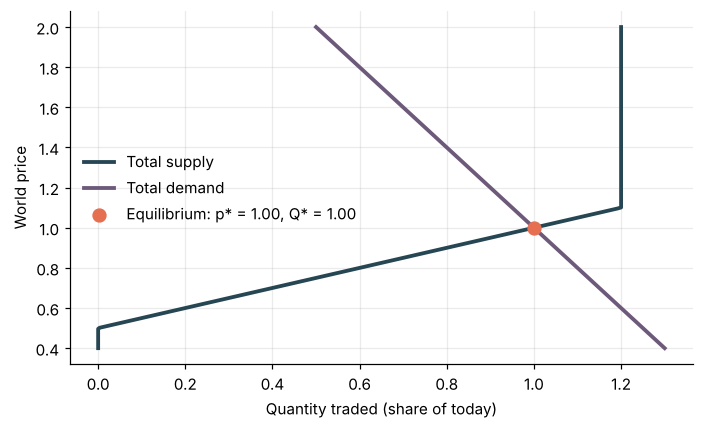

In [4]:
PARAMS = dict(cost=0.5,     # unit cost c (same for every producer; price is normalized to 1)
              eps=0.5,      # demand elasticity: B_j = eps * C_j
              spare=0.2)    # spare capacity: K_i = P_i * (1 + spare)

slope = P0 / (1 - PARAMS["cost"])             # supply slope, so S_i(1) = P_i
K0 = P0 * (1 + PARAMS["spare"])               # capacity
B = PARAMS["eps"] * C0                        # demand slope
A = C0 + B                                    # demand intercept, so D_j(1) = C_j

supply = lambda p, K=K0: np.minimum(K, np.maximum(0, slope * (p - PARAMS["cost"])))
demand = lambda p: np.maximum(0, A - B * p)

def equilibrium(K=K0):
    """World price where total supply = total demand, with production and consumption."""
    p = brentq(lambda p: demand(p).sum() - supply(p, K).sum(), 1e-6, 50)
    return p, supply(p, K), demand(p)

p_star, S_star, D_star = equilibrium()
grid = np.linspace(0.4, 2.0, 300)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot([supply(p).sum() for p in grid], grid, color=PROD_COLORS[0], lw=2.5, label="Total supply")
ax.plot([demand(p).sum() for p in grid], grid, color=MARKET_COLOR, lw=2.5, label="Total demand")
ax.scatter(S_star.sum(), p_star, color=ATTACK_COLOR, s=70, zorder=5, label=f"Equilibrium: p* = {p_star:.2f}, Q* = {S_star.sum():.2f}")
ax.set_xlabel("Quantity traded (share of today)"); ax.set_ylabel("World price"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

Supply turns vertical at 1.2, the total capacity. Removing capacity moves this wall to the left, so the price has to rise until demand falls to what is left.

---
# 4. Removing the hub

- **Targeted attack:** X loses a share $f$ of its factories, so its capacity becomes $(1-f)\,P_X$.
- **Random failure (control):** a random producer loses the same share. We run all 5 and average them (the exact expected value).

After each shock we solve the new equilibrium (Week 4: failure vs. attack).

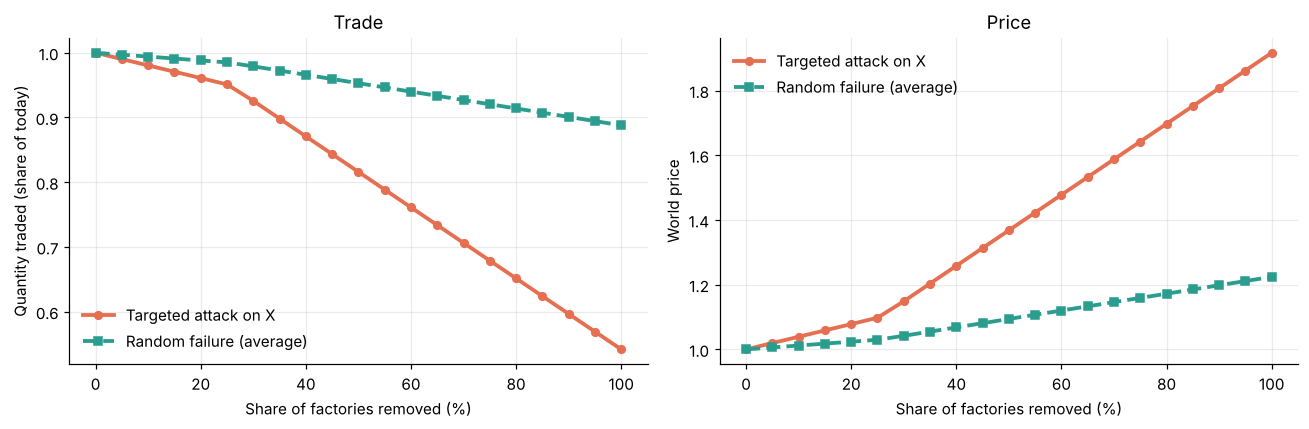

In [5]:
def shocked(k, f):
    """Capacity after producer k loses a share f of its factories."""
    K = K0.copy(); K[k] = min(K[k], (1 - f) * P0[k]); return K

F = np.linspace(0, 1, 21)
attack = np.array([equilibrium(shocked(0, f))[:2] for f in F], dtype=object)
att_p = np.array([a[0] for a in attack]);  att_q = np.array([a[1].sum() for a in attack])
rnd = [[equilibrium(shocked(k, f)) for f in F] for k in range(5)]
rnd_p = np.mean([[r[0] for r in row] for row in rnd], axis=0)
rnd_q = np.mean([[r[1].sum() for r in row] for row in rnd], axis=0)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, y1, y2, lab in [(ax[0], att_q, rnd_q, "Quantity traded (share of today)"),
                        (ax[1], att_p, rnd_p, "World price")]:
    a.plot(F * 100, y1, "o-", color=ATTACK_COLOR, lw=2.5, ms=5, label="Targeted attack on X")
    a.plot(F * 100, y2, "s--", color=RANDOM_COLOR, lw=2.5, ms=5, label="Random failure (average)")
    a.set_xlabel("Share of factories removed (%)"); a.set_ylabel(lab); a.legend(frameon=False)
ax[0].set_title("Trade"); ax[1].set_title("Price")
plt.tight_layout(); plt.show()

Losing the hub costs far more than a random failure of the same size. The other producers can grow by at most 20% (their spare capacity). Once X has lost about 30% of its factories, they are all at full capacity, so the lost output cannot be replaced: the price climbs faster and trade falls. A random failure usually hits a small producer, which the others easily cover.

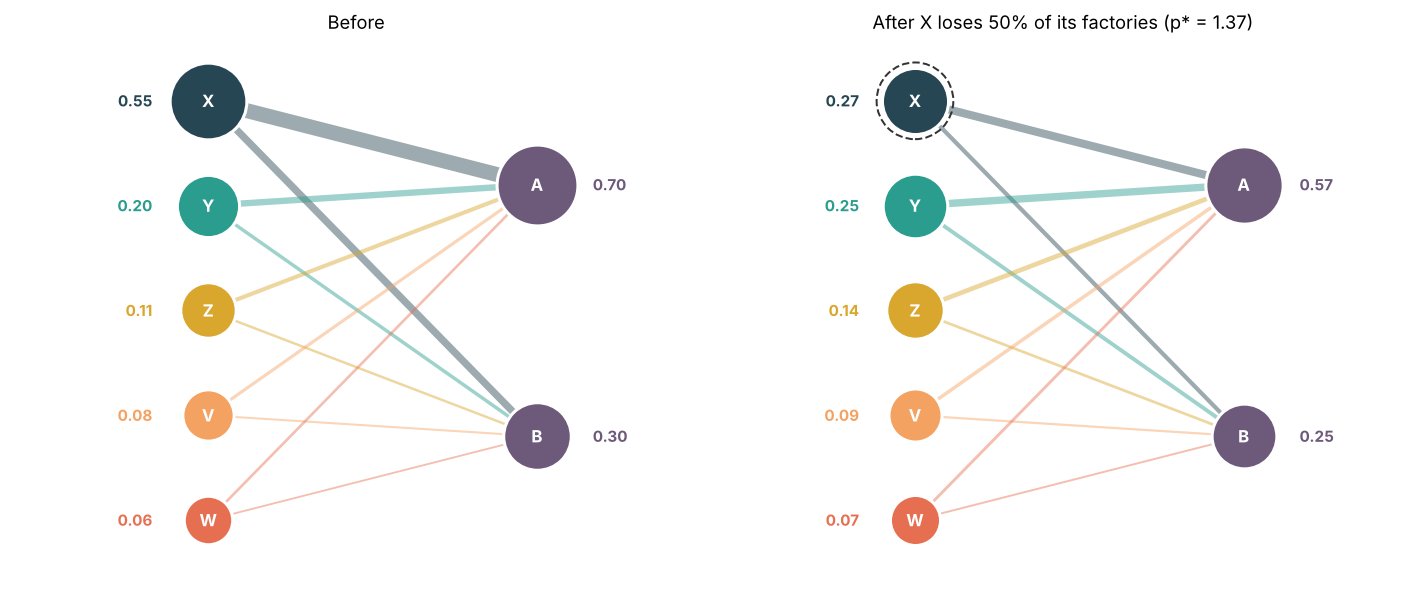

Trade change: -18.4%   Price change: 36.8%


In [6]:
# The network before and after X loses half of its factories
p_half, S_half, D_half = equilibrium(shocked(0, 0.5))
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
draw_network(G0, ax[0], "Before")
draw_network(build_network(S_half, D_half), ax[1], f"After X loses 50% of its factories (p* = {p_half:.2f})", before=G0)
plt.tight_layout(); plt.show()
print(f"Trade change: {100 * (S_half.sum() - 1):.1f}%   Price change: {100 * (p_half - 1):.1f}%")

---
**AI Prompts Used Throughout the Whole Assignment**

1. (add the prompts you used here, as in the Vilar notebook)